In [1]:
%load_ext autoreload
%autoreload 2
import pickle
from astropy.table import QTable
from astropy import units as u
from astropy.nddata import NDData, StdDevUncertainty
import numpy as np
from matplotlib import pyplot as plt


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
# import datasets
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    comb_data = pickle.load(f)
with open('data/REFLEX.p', 'rb') as g:
    errors_dict = pickle.load(g)

In [3]:
errors_dict


{'RXCJ0003.1-0605': 0.6179094419486882,
 'RXCJ0003.2-3555': 0.07247964293288481,
 'RXCJ0003.8+0203': 0.14703710320470523,
 'RXCJ0006.0-3443': 0.22761947095956642,
 'RXCJ0011.3-2851': 0.09295868677236488,
 'RXCJ0013.6-1930': 0.13354210223189258,
 'RXCJ0014.3-3023': 1.7293412740877763,
 'RXCJ0014.3-6604': 0.3376996999677323,
 'RXCJ0017.5-3509': 0.1323933419454966,
 'RXCJ0020.7-2542': 0.3062061422609284,
 'RXCJ0025.5-3302': 0.04639701540882626,
 'RXCJ0027.3-5015': 0.33035779817579547,
 'RXCJ0028.6-2338': 0.1762232582198019,
 'RXCJ0040.1-5607': 0.013688862424430896,
 'RXCJ0041.8-0918': 0.1641047451727569,
 'RXCJ0042.1-2832': 0.24537675727894,
 'RXCJ0043.4-2037': 0.8483302244986201,
 'RXCJ0049.4-2931': 0.21505671067355567,
 'RXCJ0052.7-8015': 0.6783457890981536,
 'RXCJ0056.3-0112': 0.07848718985966151,
 'RXCJ0057.8-6648': 0.2536801907396271,
 'RXCJ0102.7-2152': 0.0925488665939969,
 'RXCJ0105.5-2439': 0.6647784187183639,
 'RXCJ0106.8-0229': 0.5185702798856171,
 'RXCJ0107.8-3643': 0.148150670

In [4]:
keys = reflex_appended['OName'].tolist()
print(all(key in errors_dict for key in keys))
missing_keys = [key for key in keys if key not in errors_dict]
print(missing_keys)
print(len(missing_keys))
# could not find errors for 37 clusters

NameError: name 'reflex_appended' is not defined

In [10]:
reflex_data = comb_data[comb_data['Sub-Cat']=='REFLEX']
reflex_appended = reflex_data.copy()
reflex_appended['L_err'] = reflex_appended['OName'].apply(lambda x: errors_dict.get(x))
reflex_clean = reflex_appended[reflex_appended['L_err'].notna()]
reflex_clean

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
543,J2347.7-2808,RXCJ2347.7-2808,A4038,23 47 43.2 -28 8 29,356.930 -28.141,25.139 -75.862,0.0300,NORAS/REFLEX,REFLEX,0.601,...,0.114748,0.107849,,,,-10,-1000.0,1,NaN,0.038488
546,J2351.6-2605,RXCJ2351.6-2605,A2667,23 51 40.7 -26 5 1,357.919 -26.084,34.017 -76.609,0.2264,NORAS/REFLEX,REFLEX,3.631,...,0.365168,0.382711,,,,-10,-1000.0,1,NaN,0.993468
547,J2354.2-1024,RXCJ2354.2-1024,A2670,23 54 13.4 -10 24 46,358.556 -10.413,81.334 -68.530,0.0765,NORAS/REFLEX,REFLEX,1.450,...,0.216913,0.225417,RMJ235413.7-102508.5,,,-10,-1000.0,1,NaN,0.151354
549,J2357.0-3445,RXCJ2357.0-3445,A4059,23 57 2.3 -34 45 38,359.260 -34.761,356.359 -76.082,0.0475,NORAS/REFLEX,REFLEX,0.931,...,0.163126,0.149009,,,,-10,-1000.0,1,NaN,0.091267


In [11]:
reflex_clean['E_MSZ'].head(), reflex_clean['e_MSZ'].head, reflex_clean['MSZ'].head()

(1    0.368165
 2    0.282160
 3    0.248869
 6    0.182667
 9    0.233331
 Name: E_MSZ, dtype: float64,
 <bound method NDFrame.head of 1      0.369144
 2      0.301448
 3      0.226974
 6      0.188038
 9      0.245311
          ...   
 543    0.107849
 546    0.382711
 547    0.225417
 549    0.149009
 550    0.240743
 Name: e_MSZ, Length: 188, dtype: float64>,
 1    5.957353
 2    2.238774
 3    4.001657
 6    2.606369
 9    2.756623
 Name: MSZ, dtype: float64)

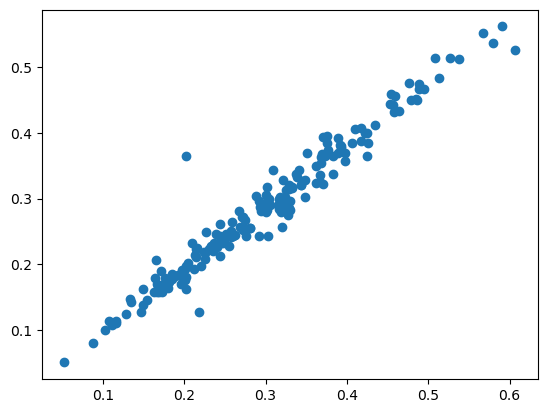

In [12]:
plt.scatter(reflex_clean['e_MSZ'], reflex_clean['E_MSZ'])

Text(0.5, 0, 'M500 (1e14 Msun)')

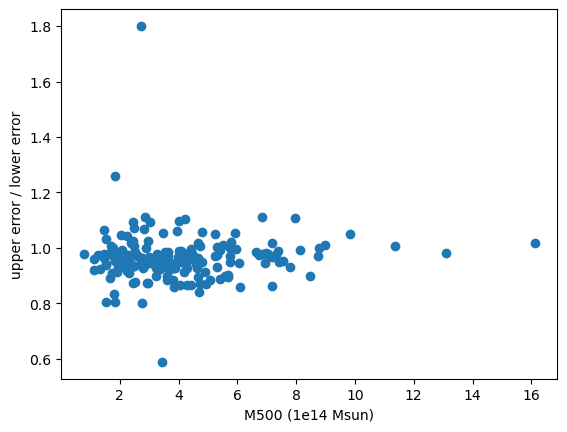

In [13]:
plt.scatter(reflex_clean['MSZ'], reflex_clean['E_MSZ']/reflex_clean['e_MSZ'])
plt.ylabel('upper error / lower error')
plt.xlabel('M500 (1e14 Msun)')

Text(0.5, 0, 'upper error / lower error')

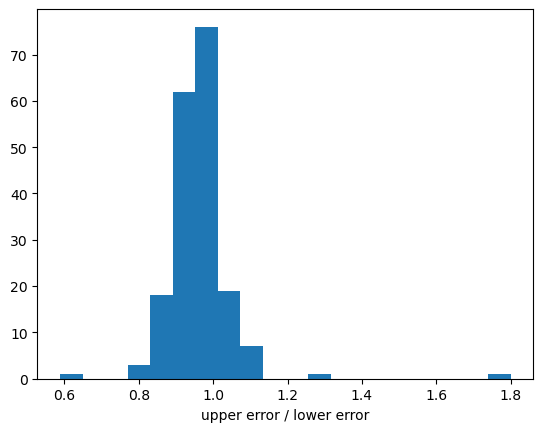

In [14]:
plt.hist(reflex_clean['E_MSZ']/reflex_clean['e_MSZ'], bins=20)
plt.xlabel('upper error / lower error')

Text(0.5, 0, 'z')

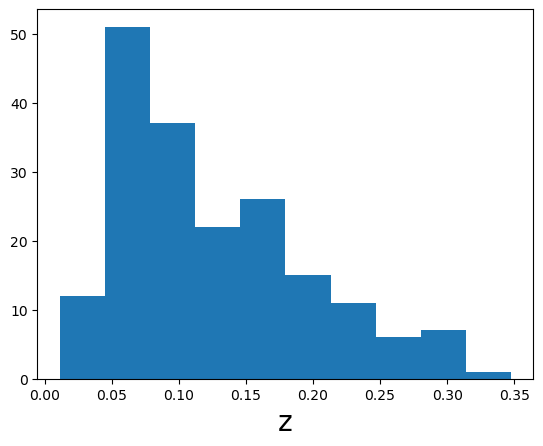

In [15]:
plt.hist(reflex_clean['z_x'])
plt.xlabel('z', size=20)

In [16]:
L_err_list = reflex_clean['L_err'].tolist()
L_err_list

[0.6179094419486882,
 0.14703710320470523,
 0.22761947095956642,
 0.09295868677236488,
 0.13354210223189258,
 0.3376996999677323,
 1.7293412740877763,
 0.3062061422609284,
 0.04639701540882626,
 0.33035779817579547,
 0.1762232582198019,
 0.1641047451727569,
 0.24537675727894,
 0.8483302244986201,
 0.07848718985966151,
 0.0925488665939969,
 0.6647784187183639,
 0.04290117582179534,
 0.014446791901477143,
 0.04427524236779236,
 0.5714405637181501,
 0.05943654764724139,
 0.5045482838885549,
 0.2867256713699702,
 0.4436884192992519,
 0.2681984406120019,
 0.5796597097222473,
 0.09100651536661837,
 0.46449603444193566,
 0.8790525964936597,
 0.1551347321172641,
 0.09000598818961687,
 0.14363824973439615,
 0.05694014240691957,
 0.10325761146446225,
 0.06122966248764443,
 0.5496809384801187,
 0.18113312845470247,
 0.0935051826076239,
 0.06905150366042391,
 0.0946826534929151,
 0.058054929209745254,
 0.06957019099946796,
 0.06425621151153069,
 0.09946722237715844,
 0.08716212177329971,
 0.292404

In [21]:
def generate_nfws_from_combined_dataset(dataset, nrows=None):
    cls_data={'M500':dataset['MSZ'],
          'L500':dataset['L500'],
          'z':dataset['z_y'] # take z from Planck
         }
    units={
        'M500': 1e14*u.Msun,
        'L500': 1e37*u.W,
        'z': None
    }
    
    #M500_err_up = np.array(dataset['E_MSZ']) 
    #M500_err_lo = np.array(dataset['e_MSZ'])
    
    #M500_err_sym = [(upper + lower) / 2 for lower, upper in zip(M500_err_lo, M500_err_up)]
    
    #uncertainties = {
    #    'M500':StdDevUncertainty(M500_err_sym)
    #}

    cls_table=QTable(cls_data, units=units)
    #cls_table['M500'].uncertainty = uncertainties['M500']
    
    n=nrows or len(cls_table)
    
    return [
        NFWProfile(
            cls_table['z'][i],
            M500=cls_table['M500'][i],
            L500=cls_table['L500'][i],
            #M500_uncertainty=uncertainties['M500'][i]

        )
        for i in range(n)
    ]

In [22]:
nfws_werr = generate_nfws_from_combined_dataset(reflex_clean)

In [25]:
i =0
nfw_test = nfws_werr[i]
print(nfw_test.L500.to(u.erg/u.s), (L_err_list[i]*1e37*u.W).to(u.erg/u.s))
print(nfw_test.M500)

6.107093999999999e+44 erg / s 6.179094419486882e+43 erg / s
5.957353 1e+14 solMass


Text(0, 0.5, 'L500 (erg/s)')

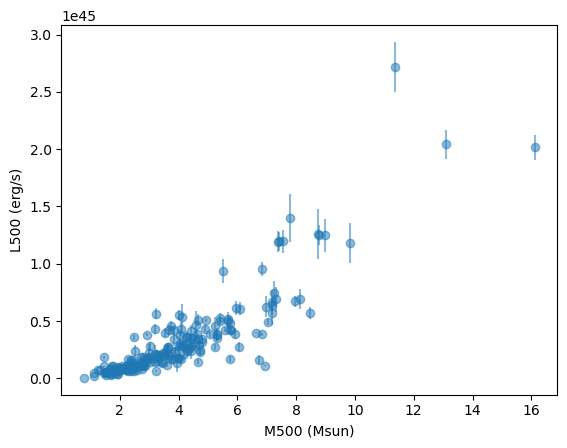

In [27]:
M500_data = [(nfw.M500).value for nfw in nfws_werr]
L500_data = [nfw.L500.to(u.erg/u.s).value for nfw in nfws_werr]
L500_errs = [(L_err_list[i]*1e37*u.W).to(u.erg/u.s).value for i in range(len(nfws_werr))]
#[plt.errorbar(nfw.M500.data*1e14*u.Msun,
#             nfw.L500.to(u.erg/u.s), 
#             yerr=(L_err_list[i])*(1e44*u.erg/u.s),
#             xerr=nfw.M500.uncertainty.array*1e14*u.Msun, 
#             marker='s') for i, nfw in enumerate(nfws_werr)]
plt.errorbar(M500_data,
             L500_data, 
             yerr=L500_errs,
             #xerr=M500_errs, 
             fmt='o', linestyle='None', alpha=0.5)
plt.xlabel('M500 (Msun)')
plt.ylabel('L500 (erg/s)')
#plt.xscale('log')
#plt.yscale('log')

In [5]:
#M_test = NDData(np.array(5*1e14*u.Msun), uncertainty = StdDevUncertainty)

In [28]:
nfw_test = nfws_werr[0]

In [30]:
nfw_test.P500_planelles()#, nfw_test.P500_planelles_test()

<Quantity 2.05185171e-11 erg / cm3>

In [8]:
x = np.logspace(-2, 1)
Pgs = nfw_test.Pg(x)#.data
Pgs_unc = nfw_test.Pg(x)#.uncertainty.array
plt.errorbar(x, Pgs, yerr=Pgs_unc, linestyle='-', capsize=3, label='new function')
plt.yscale('log')
plt.xscale('log')
plt.xlabel('r/r500')
plt.ylabel('Pg (erg/cm3)')

Pgs_test = nfw_test.Pg_test(x)
#plt.plot(x, Pgs_test)
plt.plot(x, Pgs_test, label='previous function')

rs = np.logspace(-2, 1)*u.Mpc
Pgrs = nfw_test.Pg_r(rs)


plt.legend()



NameError: name 'nfw_test' is not defined

In [9]:
Pgs, Pgs_unc

NameError: name 'Pgs' is not defined

In [73]:
nfws = generate_nfws_from_combined_dataset(reflex_clean)
L_obs = [nfw.L500.to(u.erg/u.s) for nfw in nfws]

In [32]:
L_obs

[<Quantity 6.107094e+44 erg / s>,
 <Quantity 8.46881e+43 erg / s>,
 <Quantity 1.809494e+44 erg / s>,
 <Quantity 1.086002e+44 erg / s>,
 <Quantity 1.236332e+44 erg / s>,
 <Quantity 2.827248e+44 erg / s>,
 <Quantity 1.1818114e+45 erg / s>,
 <Quantity 2.872451e+44 erg / s>,
 <Quantity 4.9467e+43 erg / s>,
 <Quantity 2.164603e+44 erg / s>,
 <Quantity 1.404549e+44 erg / s>,
 <Quantity 5.100085e+44 erg / s>,
 <Quantity 2.734146e+44 erg / s>,
 <Quantity 6.907787e+44 erg / s>,
 <Quantity 1.437223e+44 erg / s>,
 <Quantity 1.460216e+44 erg / s>,
 <Quantity 5.160525e+44 erg / s>,
 <Quantity 4.91051e+43 erg / s>,
 <Quantity 1.81484e+43 erg / s>,
 <Quantity 4.67516e+43 erg / s>,
 <Quantity 4.979596e+44 erg / s>,
 <Quantity 7.63259e+43 erg / s>,
 <Quantity 5.701343e+44 erg / s>,
 <Quantity 2.010759e+44 erg / s>,
 <Quantity 4.237381e+44 erg / s>,
 <Quantity 1.768408e+44 erg / s>,
 <Quantity 6.076038e+44 erg / s>,
 <Quantity 6.69697e+43 erg / s>,
 <Quantity 3.639374e+44 erg / s>,
 <Quantity 6.258801e+

In [33]:
variances = (np.array(L_err_list)*1e37*u.W).to(1e44*u.erg/u.s)

In [34]:
len(nfws), len(L_err_list)

(188, 188)

In [35]:
L_err_list

[0.6179094419486882,
 0.14703710320470523,
 0.22761947095956642,
 0.09295868677236488,
 0.13354210223189258,
 0.3376996999677323,
 1.7293412740877763,
 0.3062061422609284,
 0.04639701540882626,
 0.33035779817579547,
 0.1762232582198019,
 0.1641047451727569,
 0.24537675727894,
 0.8483302244986201,
 0.07848718985966151,
 0.0925488665939969,
 0.6647784187183639,
 0.04290117582179534,
 0.014446791901477143,
 0.04427524236779236,
 0.5714405637181501,
 0.05943654764724139,
 0.5045482838885549,
 0.2867256713699702,
 0.4436884192992519,
 0.2681984406120019,
 0.5796597097222473,
 0.09100651536661837,
 0.46449603444193566,
 0.8790525964936597,
 0.1551347321172641,
 0.09000598818961687,
 0.14363824973439615,
 0.05694014240691957,
 0.10325761146446225,
 0.06122966248764443,
 0.5496809384801187,
 0.18113312845470247,
 0.0935051826076239,
 0.06905150366042391,
 0.0946826534929151,
 0.058054929209745254,
 0.06957019099946796,
 0.06425621151153069,
 0.09946722237715844,
 0.08716212177329971,
 0.292404

In [36]:
#TODO: update with mass
def log_lik(p0, obs, variances, nfws):
    log_s0 = p0
    s0 = 10**log_s0*u.cm**2
    mx = 1e-2*u.GeV
    # prior
    if log_s0>0:
        return -np.inf
    # calculate model predicted L500
    predicted = [nfw.solve_for_L500(s0, mx) for nfw in nfws]
    X2 = chi_squared(predicted, obs, variances)
    return -X2/2

In [49]:
#TODO: update with mass
def log_lik_analytic(p0, obs, variances, nfws):
    log_s0 = p0
    if log_s0>0: #prior
        return -np.inf
    s0 = 10**log_s0*u.cm**2
    mx = 1e-2*u.GeV
    # calculate model predicted L500
    predicted = [nfw.L500_analytic(s0, mx) for nfw in nfws]
    X2 = chi_squared(predicted, obs, variances)
    return -X2/2

In [74]:
nfws_subset = nfws[:10]
vars_subset = variances[:10]
obs_subset = L_obs[:10]

In [39]:
log_lik(-25, obs_subset, vars_subset, nfws_subset)

<Quantity -7.65606452e+08>

In [40]:
loglik25 = log_lik(-25, obs_subset, vars_subset, nfws)

KeyboardInterrupt: 

In [ ]:
loglik25

In [ ]:
loglik30 = log_lik(-30, obs_subset, vars_subset, nfws)

In [ ]:
loglik45 = log_lik(-45, obs_subset, vars_subset, nfws)

In [ ]:
plt.plot([-25, -30, -45], [loglik25, loglik30, loglik45])
plt.xlabel('log(sigma0/cm2)')
plt.ylabel('log likelihood')

In [41]:
loglikanalytic_25 = log_lik_analytic(-25, obs_subset, vars_subset, nfws)
loglikanalytic_30 = log_lik_analytic(-30, obs_subset, vars_subset, nfws)
loglikanalytic_35 = log_lik_analytic(-35, obs_subset, vars_subset, nfws)

In [42]:
loglikanalytic_40 = log_lik_analytic(-40, obs_subset, vars_subset, nfws)

In [43]:
loglikanalytic_27 = log_lik_analytic(-27, obs_subset, vars_subset, nfws)

In [44]:
loglikanalytic_26 = log_lik_analytic(-26, obs_subset, vars_subset, nfws)

In [45]:
loglikanalytic_255 = log_lik_analytic(-25.5, obs_subset, vars_subset, nfws)

In [46]:
loglikanalytic_2525 = log_lik_analytic(-25.25, obs_subset, vars_subset, nfws)

In [47]:
print(loglikanalytic_25, loglikanalytic_27, loglikanalytic_30, loglikanalytic_35, loglikanalytic_40)

-765606451.6133116 -353058.8669734924 -296521.05941998085 -296468.45951080427 -296468.4589848438


(-1000000.0, 0.0)

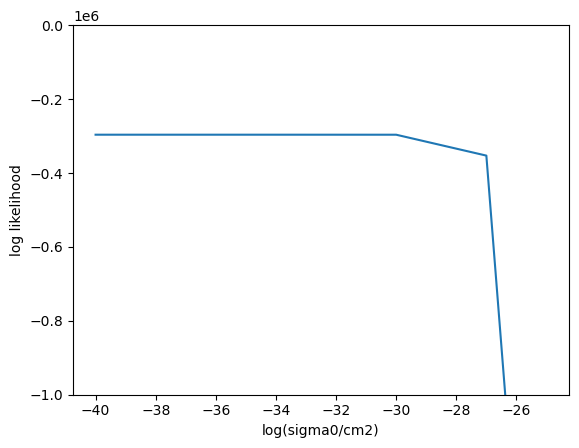

In [48]:
plt.plot([-25, -25.25, -25.5, -26, -27, -30, -35, -40], [loglikanalytic_25, loglikanalytic_2525, loglikanalytic_255, loglikanalytic_26, loglikanalytic_27, loglikanalytic_30, loglikanalytic_35, loglikanalytic_40])
plt.xlabel('log(sigma0/cm2)')
plt.ylabel('log likelihood')
plt.ylim(-1e6, 0)

In [50]:
s0 = 10**-25*u.cm**2
mx = 1e-2*u.GeV
nfws[10].solve_for_L500(s0, mx),nfws[10].L500_analytic(s0, mx)

(<Quantity 1.24432086e+46 erg / s>, <Quantity 1.24432086e+46 erg / s>)

In [51]:
nfws[10].get_Mbh()

<Quantity 1.137795e+10 solMass>

In [52]:
m_chi=-2
ndim, nwalkers = 1, 5
p0=np.zeros((nwalkers, ndim ))
log_sigma0 = np.random.uniform(low=-50, high=-20, size=nwalkers).astype(np.float128)

In [53]:
[nfw.total_heating_rate(0.015*nfw.R500, nfw.R500, 0.1*nfw.R500) - nfw.total_cooling_rate(0.015*nfw.R500, nfw.R500) for nfw in nfws_subset]

[<Quantity -2.46469448e+45 erg / s>,
 <Quantity -4.75797013e+44 erg / s>,
 <Quantity -1.25733903e+45 erg / s>,
 <Quantity -5.85650081e+44 erg / s>,
 <Quantity -6.64821424e+44 erg / s>,
 <Quantity -7.38704716e+44 erg / s>,
 <Quantity -5.61264122e+45 erg / s>,
 <Quantity -1.36390868e+45 erg / s>,
 <Quantity -1.90605568e+44 erg / s>,
 <Quantity -1.03050447e+45 erg / s>]

In [54]:
Linj_bh = [nfw.get_Linj_from_L500() for nfw in nfws]
Linj_bh

[<Quantity 6.28951489e+44 erg / s>,
 <Quantity 2.96874235e+44 erg / s>,
 <Quantity 3.96160997e+44 erg / s>,
 <Quantity 3.26298921e+44 erg / s>,
 <Quantity 3.42776738e+44 erg / s>,
 <Quantity 4.69373195e+44 erg / s>,
 <Quantity 8.08292048e+44 erg / s>,
 <Quantity 4.72210891e+44 erg / s>,
 <Quantity 2.42013681e+44 erg / s>,
 <Quantity 4.24076041e+44 erg / s>,
 <Quantity 3.5980237e+44 erg / s>,
 <Quantity 5.87326258e+44 erg / s>,
 <Quantity 4.63438646e+44 erg / s>,
 <Quantity 6.59096183e+44 erg / s>,
 <Quantity 3.62960346e+44 erg / s>,
 <Quantity 3.65156049e+44 erg / s>,
 <Quantity 5.89961508e+44 erg / s>,
 <Quantity 2.41339333e+44 erg / s>,
 <Quantity 1.65332628e+44 erg / s>,
 <Quantity 2.36876873e+44 erg / s>,
 <Quantity 5.82014442e+44 erg / s>,
 <Quantity 2.85374613e+44 erg / s>,
 <Quantity 6.12733076e+44 erg / s>,
 <Quantity 4.12360263e+44 erg / s>,
 <Quantity 5.47390248e+44 erg / s>,
 <Quantity 3.92718481e+44 erg / s>,
 <Quantity 6.27734189e+44 erg / s>,
 <Quantity 2.71539975e+44 erg

In [55]:
Linj_Mvir = [nfw.Linj(0.3*nfw.R500) for nfw in nfws]
Linj_Mvir

AttributeError: 'NFWProfile' object has no attribute 'Mvir'

In [56]:
# eddington luminosity
L_edds = [(10**(47.5) * u.erg/u.s * nfw.get_Mbh()/(10**(9.5)*u.Msun)).value for nfw in nfws]
L_edds

[1.9889192437054062e+48,
 9.387987615164317e+47,
 1.2527710707455218e+48,
 1.031847788058194e+48,
 1.0839552218684025e+48,
 1.4842883683155704e+48,
 2.5560438878496867e+48,
 1.4932619502849557e+48,
 7.6531445750597e+47,
 1.341046192037082e+48,
 1.1377949976675248e+48,
 1.85728870424574e+48,
 1.4655216770385097e+48,
 2.084245134467512e+48,
 1.1477813937459067e+48,
 1.1547248154830616e+48,
 1.8656220960313185e+48,
 7.63181980919868e+47,
 5.228276775175988e+47,
 7.49070444585663e+47,
 1.8404912690517036e+48,
 9.024337621687263e+47,
 1.937632116780656e+48,
 1.3039976480221756e+48,
 1.7309999513557006e+48,
 1.2418848782468928e+48,
 1.9850698029894252e+48,
 8.586847980360836e+47,
 1.6337670822552862e+48,
 2.0075512195770267e+48,
 6.594459842055971e+47,
 1.0103457719726119e+48,
 1.6634435417803115e+48,
 8.20220722310394e+47,
 1.1568686422924466e+48,
 1.0374839250560704e+48,
 1.7130530796191227e+48,
 9.27470648432732e+47,
 1.4717680697127274e+48,
 7.898647304662772e+47,
 1.0720436373792664e+48

In [57]:
sample_nfw = nfws[10]
print(sample_nfw.L500, sample_nfw.get_Mbh(), sample_nfw.get_Linj_from_L500())
print(sample_nfw.total_heating_rate(0.01*sample_nfw.R500, sample_nfw.R500, 0.1*sample_nfw.R500))
print(sample_nfw.total_cooling_rate(0.01*sample_nfw.R500, sample_nfw.R500))


1.404549 1e+37 W 11377949976.675247 solMass 3.598023702975347e+44 erg / s
4.025766749627538e+44 erg / s
1.0653557000317866e+45 erg / s


In [58]:
cooling_rates

NameError: name 'cooling_rates' is not defined

In [64]:
heatings=[n.total_heating_rate(0.0001*n.R500, 1*n.R500, rc=0.1*n.R500).value for n in nfws]

In [65]:
coolings = [n.total_cooling_rate(0.0001*n.R500, 1*n.R500).value for n in nfws]

In [70]:
diff = np.subtract(heatings, coolings)
diff

array([-2.30560966e+45, -3.93567277e+44, -1.15531448e+45, -4.92133170e+44,
       -5.68698215e+44, -5.96777066e+44, -5.46305016e+45, -1.23496604e+45,
       -1.20149538e+44, -9.13693182e+44, -5.99080415e+44, -1.27381263e+45,
       -8.59132173e+44, -4.14827549e+45, -8.08938705e+44, -6.22323863e+44,
       -2.16081066e+45, -2.77900982e+44, -1.07028872e+44, -1.52117550e+44,
       -2.16911260e+45, -1.43676535e+44, -4.03070270e+45, -9.38857364e+44,
       -8.71167838e+44, -1.20579743e+45, -2.35174565e+45, -5.38345439e+44,
       -1.32779383e+45, -3.09511528e+45, -3.64825212e+44, -1.33331492e+44,
       -3.66540149e+44, -2.40643343e+44, -7.72282281e+44, -4.41343223e+45,
       -1.28996665e+45, -6.54807223e+44, -1.08385005e+45, -1.43349758e+44,
       -4.07570572e+44, -2.39099875e+44, -2.34821361e+45, -4.08628803e+44,
       -4.82934044e+44, -4.53577220e+44, -9.20106236e+44, -3.22558472e+45,
       -2.42597808e+44, -2.13269931e+45, -3.60467252e+44, -4.44113049e+45,
       -2.97646770e+44, -

Text(0, 0.5, 'agn heating - radiative cooling (erg/s)')

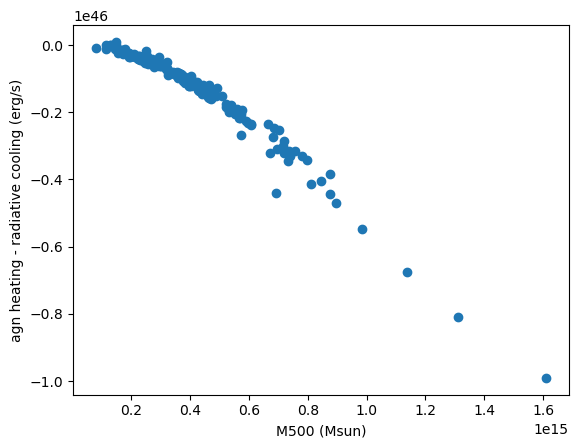

In [71]:
plt.scatter([nfw.M500.to(u.Msun).value for nfw in nfws], diff)
plt.xlabel('M500 (Msun)')
plt.ylabel('agn heating - radiative cooling (erg/s)')

In [72]:
np.median(heatings)

6.104600583434481e+44